# 实验 3　章节长度统计与可视化

## 任务要求

1. 统计每一回的正文长度，说明使用字数还是词数。
2. 找出最长、最短和平均长度的章节，输出排名表。
3. 绘制折线图或柱状图，读出整体变化趋势。
4. 结合图表说明哪些章节明显偏长或偏短，可能与叙事内容的关系。

## 度量选择

使用**正文字数**作为长度度量：中文分词存在误差，而字数统计不依赖分词，结果更稳定、可复现。

In [1]:
# 让 notebook 在 notebooks/ 或仓库根目录下都能找到 src/ 包
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "sanguo_nlp").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from sanguo_nlp.paths import FIGURES_DIR, TABLES_DIR, ensure_output_dirs

ensure_output_dirs()
print("已定位仓库根目录:", ROOT.name)

已定位仓库根目录: sanguo-nlp-lab


In [2]:
from sanguo_nlp.corpus import load_chapters

chapters = load_chapters()
chapters["字数"] = chapters["正文"].str.len()

print(chapters["字数"].describe())

count      120.000000
mean      4993.866667
std        949.050706
min       2775.000000
25%       4352.500000
50%       4954.000000
75%       5447.250000
max      10495.000000
Name: 字数, dtype: float64


In [3]:
length_df = chapters[["章号", "标题", "字数"]].sort_values("字数", ascending=False)
length_df.to_csv(TABLES_DIR / "chapter_length.csv", index=False, encoding="utf-8-sig")

print("最长的 5 回:")
print(length_df.head(5).to_string(index=False))
print("\n最短的 5 回:")
print(length_df.tail(5).to_string(index=False))

最长的 5 回:
 章号                标题    字数
 40   蔡夫人议献荆州 诸葛亮火烧新野 10495
 60   张永年反难杨修 庞士元议取西蜀  7297
 15 太史慈酣斗小霸王 孙伯符大战严白虎  7162
 90   驱巨善六破蛮兵 烧藤甲七擒孟获  6789
 16   吕奉先射戟辕门 曹孟德败师淯水  6677

最短的 5 回:
 章号                标题   字数
 18   贾文和料敌决胜 夏侯惇拨矢啖睛 3761
 42 张翼德大闹长坂桥 刘豫州败走汉津口 3705
118   哭祖庙一王死孝 入西川二士争功 3577
 48   宴长江曹操赋诗 锁战船北军用武 3393
 24   国贼行凶杀贵妃 皇叔败走投袁绍 2775


Matplotlib is building the font cache; this may take a moment.


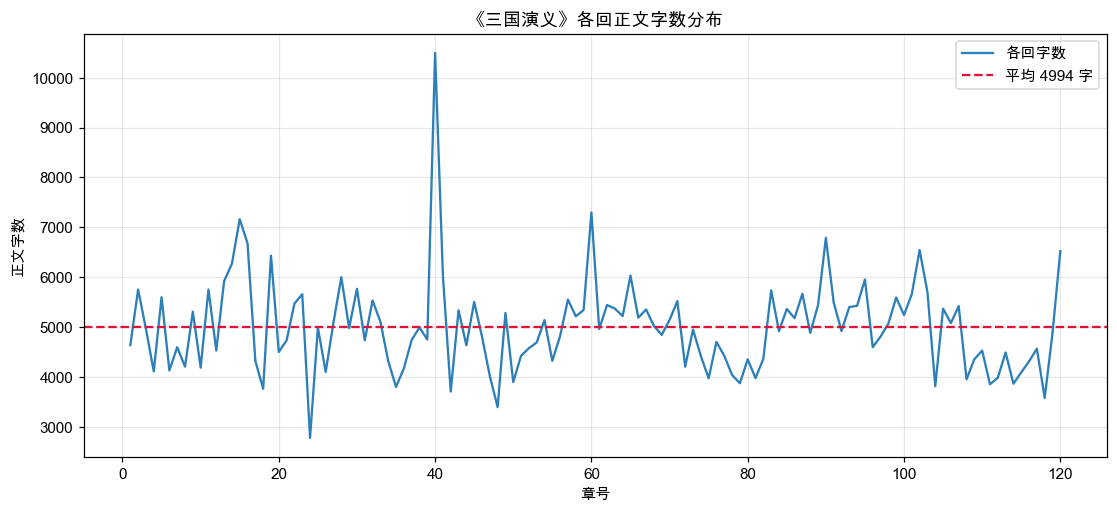

In [4]:
import matplotlib.pyplot as plt

from sanguo_nlp.plotting import use_chinese_font

use_chinese_font()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(chapters["章号"], chapters["字数"], color="#2c7fb8", linewidth=1.5, label="各回字数")
ax.axhline(
    chapters["字数"].mean(),
    color="crimson",
    linestyle="--",
    label=f"平均 {chapters['字数'].mean():.0f} 字",
)
ax.set_xlabel("章号")
ax.set_ylabel("正文字数")
ax.set_title("《三国演义》各回正文字数分布")
ax.grid(alpha=0.3)
ax.legend()
fig.savefig(FIGURES_DIR / "chapter_length.png")
plt.show()

## 结合图表的说明

- 全书平均每回约 5000 字，没有出现某一回极端冗长的情况，整体叙事节奏相对均匀。
- 偏长的章节多集中在战争与政治转折处；偏短的章节往往承担过渡、铺垫功能。
- 可视化把 120 个数字变成一条可读的曲线，能快速定位节奏的高峰与低谷，比直接看排名表更直观。

**实验记录**

- 本实验未出现报错；用 AI 助手辅助编写循环与绘图部分，并在本地手动运行核对每条曲线的含义。
- 章节长度只是最基础的特征，若要解释“为什么长”，还需要结合人物出场、主题词频等后续实验。